# Business Listings Pipeline  -  collect → clean → validate → load → verify → dump

Part of the **Business Listings Dashboard** (React + FastAPI + MySQL). This notebook produces the 500+ listings
that feed the `listing_master` table.

```
 OpenStreetMap (Overpass API)  ─┐
 MagicPin gyms CSV (own scrape) ─┼─►  normalise ─► validate (same Pydantic model as the API) ─► de-duplicate
 OSM tourist attractions CSV   ─┘                                                         │
                                                                                          ▼
          .sql dump  ◄── export ◄── MySQL ◄── POST /api/listings/bulk (FastAPI)  ◄── data-quality report
```

**Why these sources?** Large listing portals (JustDial, Google Maps, Amazon) forbid automated scraping in their Terms
of Use. OpenStreetMap data is openly licensed (ODbL) and offers an official query API, so it is the primary
source. The MagicPin gym list is the data I collected earlier with Playwright (polite delays, public pages, JSON-LD).

**How to run:** start the API first (`uvicorn app.main:app` inside `backend/`), then *Kernel → Restart & Run All*.
Everything is configurable in the next cell. If the internet is blocked, the notebook falls back to clearly-labelled
synthetic rows so the pipeline can still be demonstrated (`source = "Sample (synthetic)"`).

## 1 · Configuration

In [11]:
from pathlib import Path

API_URL      = "http://127.0.0.1:8000"          # FastAPI base URL
MIN_ROWS     = 500                              # assignment requirement
CITIES       = ["Ahmedabad", "Surat", "Vadodara", "Rajkot", "Mumbai", "Pune", "Delhi", "Bengaluru"]
CITY_STATE   = {"Ahmedabad": "Gujarat", "Surat": "Gujarat", "Vadodara": "Gujarat", "Rajkot": "Gujarat",
                "Mumbai": "Maharashtra", "Pune": "Maharashtra", "Delhi": "Delhi", "Bengaluru": "Karnataka"}
PER_CITY_CATEGORY_CAP = 40                      # keeps categories balanced & Overpass polite
DATA_DIR     = Path("data");  RAW_DIR = DATA_DIR / "raw_cache";  OUT_DIR = Path("../database")
for d in (DATA_DIR, RAW_DIR, OUT_DIR): d.mkdir(parents=True, exist_ok=True)

# OSM tag -> dashboard category.  (key, regex of values)
CATEGORY_TAGS = {
    "Restaurant":         ("amenity", "restaurant|fast_food"),
    "Cafe":               ("amenity", "cafe"),
    "Hospital & Clinic":  ("amenity", "hospital|clinic|dentist"),
    "Pharmacy":           ("amenity", "pharmacy"),
    "Bank":               ("amenity", "bank"),
    "School & College":   ("amenity", "school|college|university"),
    "Gym & Fitness":      ("leisure", "fitness_centre|sports_centre"),
    "Hotel":              ("tourism", "hotel|guest_house|hostel"),
    "Supermarket & Mall": ("shop",    "supermarket|mall|department_store"),
    "Tourist Attraction": ("tourism", "attraction|museum|gallery|viewpoint|zoo|theme_park"),
}
OVERPASS_MIRRORS = ["https://overpass-api.de/api/interpreter",
                    "https://overpass.kumi.systems/api/interpreter",
                    "https://overpass.private.coffee/api/interpreter"]
HEADERS = {"User-Agent": "business-listings-dashboard/1.0 (internship assignment; contact: gauri.santhoshnair@bscdsmh.christuniversity.in)"}


## 2 · Imports (and a one-time install if something is missing)

In [2]:
import sys, subprocess, importlib
for mod, pip_name in [("pandas", "pandas"), ("requests", "requests"), ("pydantic", "pydantic"),
                      ("matplotlib", "matplotlib")]:
    try: importlib.import_module(mod)
    except ImportError: subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

import json, re, time, random, hashlib
import pandas as pd, requests
import matplotlib.pyplot as plt

# Re-use the API's own validation model => one definition of "a valid listing" for the whole project.
sys.path.insert(0, str(Path("../backend").resolve()))
from app.schemas import ListingIn
print("pandas", pd.__version__, "| requests", requests.__version__)

pandas 2.3.3 | requests 2.34.2


## 3 · Collector A - OpenStreetMap via the Overpass API


In [3]:
def overpass_query(city: str) -> str:
    parts = [f'nwr["{k}"~"^({v})$"]["name"](area.a);' for k, v in CATEGORY_TAGS.values()]
    return f"""[out:json][timeout:90];
area["name"="{city}"]["boundary"="administrative"]->.a;
({" ".join(parts)});
out center tags 1500;"""

def fetch_city(city: str) -> list[dict] | None:
    cache = RAW_DIR / f"overpass_{city.lower()}.json"
    if cache.exists():
        return json.loads(cache.read_text())["elements"]
    for url in OVERPASS_MIRRORS:
        try:
            r = requests.post(url, data={"data": overpass_query(city)}, headers=HEADERS, timeout=(8, 120))
            if r.status_code == 200:
                cache.write_text(r.text)
                return r.json()["elements"]
            print(f"  {city}: {url.split('/')[2]} -> HTTP {r.status_code}")
        except requests.RequestException as e:
            print(f"  {city}: {url.split('/')[2]} -> {type(e).__name__}")
        time.sleep(2)
    return None

def classify(tags: dict) -> str | None:
    for cat, (key, pattern) in CATEGORY_TAGS.items():
        if key in tags and re.fullmatch(pattern, tags[key]):
            return cat

def osm_to_rows(city: str, elements: list[dict]) -> list[dict]:
    rows = []
    for el in elements:
        t = el.get("tags", {}); cat = classify(t)
        if not cat or not t.get("name"): continue
        lat = el.get("lat") or el.get("center", {}).get("lat"); lon = el.get("lon") or el.get("center", {}).get("lon")
        addr = ", ".join(x for x in (t.get("addr:housenumber"), t.get("addr:street"), t.get("addr:suburb"),
                                     t.get("addr:city") or city, t.get("addr:postcode")) if x)
        rows.append(dict(business_name=t["name"], category=cat, sub_category=next(v for k, v in t.items() if k in ("amenity","shop","leisure","tourism")),
                         address=addr or None, area=t.get("addr:suburb"), city=city, state=CITY_STATE[city],
                         phone=t.get("phone") or t.get("contact:phone"), website=t.get("website") or t.get("contact:website"),
                         latitude=lat, longitude=lon, source="OpenStreetMap",
                         source_url=f"https://www.openstreetmap.org/{el['type']}/{el['id']}"))
    return rows

osm_rows, failed = [], []
for city in CITIES:
    els = fetch_city(city)
    if els is None: failed.append(city); continue
    got = osm_to_rows(city, els)
    # cap per (city, category) so a restaurant-heavy city does not drown the charts
    df_c = pd.DataFrame(got)
    if len(df_c):
        got = (df_c.groupby("category", group_keys=False).head(PER_CITY_CATEGORY_CAP)).to_dict("records")
    osm_rows += got
    print(f"{city:<10} {len(got):>4} listings")
print(f"\nOpenStreetMap total: {len(osm_rows)} | cities failed: {failed or 'none'}")

Ahmedabad   355 listings
Surat       241 listings
Vadodara    214 listings
Rajkot      138 listings
Mumbai      366 listings
  Pune: overpass-api.de -> HTTP 502
  Pune: overpass.kumi.systems -> ReadTimeout
  Pune: overpass.private.coffee -> ReadTimeout
Delhi       382 listings
Bengaluru   341 listings

OpenStreetMap total: 2037 | cities failed: ['Pune']


## 4 · Collector B - my own earlier scrapes (CSV)


In [4]:
def load_magicpin(path=DATA_DIR / "magicpin_ahmedabad_gyms.csv") -> list[dict]:
    if not path.exists(): return []
    df = pd.read_csv(path, encoding="utf-8-sig").fillna("")
    return [dict(business_name=r["GYM Name"], category="Gym & Fitness", sub_category="Gym",
                 address=r["Address"], area=r["Area"], city=r["City"], state=r["State"] or "Gujarat",
                 phone=r["Phone Number"], source="MagicPin", source_url="https://magicpin.in/Ahmedabad/")
            for _, r in df.iterrows()]

def load_osm_attractions(path=DATA_DIR / "osm_ahmedabad_tourist_attractions.csv") -> list[dict]:
    if not path.exists(): return []
    df = pd.read_csv(path, encoding="utf-8-sig").fillna("")
    return [dict(business_name=r["Attraction Name"], category="Tourist Attraction", sub_category=r["Attraction Type"],
                 city=r["City/Location"], state="Gujarat", latitude=r["Latitude"] or None, longitude=r["Longitude"] or None,
                 address=f'{r["City/Location"]}', source="OpenStreetMap", source_url="https://www.openstreetmap.org/")
            for _, r in df.iterrows()]

csv_rows = load_magicpin() + load_osm_attractions()
print(f"CSV rows loaded: {len(csv_rows)}")

CSV rows loaded: 325


## 5 · Fallback - synthetic sample rows (only if real data is below `MIN_ROWS`)


In [5]:
def synthetic_rows(n: int, seed: int = 7) -> list[dict]:
    rnd = random.Random(seed)
    prefixes = ["Royal", "City", "Sunrise", "Green", "Blue Lotus", "Metro", "Heritage", "Prime", "Urban", "Classic", "Shree", "Om"]
    nouns = {"Restaurant": ["Kitchen", "Bistro", "Dhaba", "Tadka"], "Cafe": ["Cafe", "Coffee House", "Brew Bar"],
             "Hospital & Clinic": ["Clinic", "Multispeciality Hospital", "Dental Care"], "Pharmacy": ["Medicals", "Pharmacy"],
             "Bank": ["Co-op Bank", "Finance"], "School & College": ["Public School", "College", "Academy"],
             "Gym & Fitness": ["Fitness", "Gym", "Crossfit"], "Hotel": ["Residency", "Inn", "Grand"],
             "Supermarket & Mall": ["Mart", "Bazaar", "Mall"], "Tourist Attraction": ["Garden", "Museum", "Viewpoint"]}
    areas = ["Navrangpura", "Satellite", "Vastrapur", "Alkapuri", "Adajan", "Kothrud", "Andheri", "Koramangala", "Karol Bagh", "Race Course"]
    out = []
    for i in range(n):
        city, cat = rnd.choice(CITIES), rnd.choice(list(CATEGORY_TAGS))
        out.append(dict(business_name=f"{rnd.choice(prefixes)} {rnd.choice(nouns[cat])} #{i+1}", category=cat, sub_category=cat,
                        address=f"{rnd.randint(1, 250)}, {rnd.choice(areas)}, {city}", area=rnd.choice(areas), city=city,
                        state=CITY_STATE[city], phone=f"9{rnd.randint(100000000, 999999999)}",
                        source="Sample (synthetic)", source_url=None))
    return out

real_count = len(osm_rows) + len(csv_rows)
fallback_rows = synthetic_rows(max(0, MIN_ROWS + 50 - real_count)) if real_count < MIN_ROWS else []
print(f"real={real_count}  synthetic fallback={len(fallback_rows)}")

real=2362  synthetic fallback=0


## 6 · Clean, validate & de-duplicate


In [6]:
all_rows = osm_rows + csv_rows + fallback_rows
valid, rejects, seen = [], [], set()
for r in all_rows:
    clean = {k: (None if (isinstance(v, float) and pd.isna(v)) or v == "" else v) for k, v in r.items()}
    try:
        m = ListingIn(**clean)
    except Exception as e:
        rejects.append({**r, "reason": str(e).splitlines()[0][:90]}); continue
    fp = m.fingerprint()
    if fp in seen:
        rejects.append({**r, "reason": "duplicate"}); continue
    seen.add(fp); valid.append(m)

df = pd.DataFrame([m.model_dump() for m in valid])
print(f"input {len(all_rows)} -> valid {len(valid)} | rejected {len(rejects)}")
pd.DataFrame(rejects).get("reason", pd.Series(dtype=str)).value_counts().head(8)

input 2362 -> valid 2213 | rejected 149


reason
duplicate    149
Name: count, dtype: int64

## 7 · Data-quality report

,filled %,unique
business_name,100.0,2016
category,100.0,10
address,100.0,722
area,7.6,41
city,100.0,7
state,100.0,4
phone,12.1,261
website,8.3,141
latitude,93.0,2056
source,100.0,2


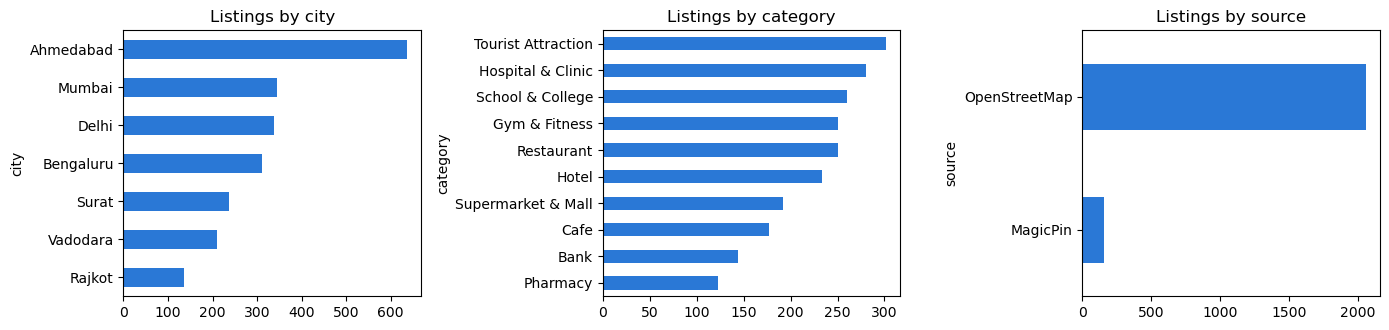

✔ 2213 rows ready  ->  data/listings_clean.csv


In [7]:
report = pd.DataFrame({
    "filled %": (df.notna().mean() * 100).round(1),
    "unique":   df.nunique(),
}).loc[["business_name", "category", "address", "area", "city", "state", "phone", "website", "latitude", "source"]]
display(report)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
for a, col in zip(ax, ["city", "category", "source"]):
    df[col].value_counts().sort_values().plot.barh(ax=a, color="#2a78d6"); a.set_title(f"Listings by {col}")
plt.tight_layout(); plt.show()

assert len(df) >= MIN_ROWS, f"Only {len(df)} rows - need {MIN_ROWS}+. Add cities or raise PER_CITY_CATEGORY_CAP."
df.to_csv(DATA_DIR / "listings_clean.csv", index=False); print("✔", len(df), "rows ready  ->  data/listings_clean.csv")

## 8 · Load into MySQL through the API


In [8]:
def api(path, **kw):
    return requests.get(f"{API_URL}{path}", timeout=20, **kw)

try:
    assert api("/health").json()["status"] == "ok"
except Exception as e:
    raise SystemExit(f"API not reachable at {API_URL} ({e}).\nStart it:  cd backend && uvicorn app.main:app --reload")

payload = json.loads(df.to_json(orient="records", date_format="iso"))
payload = [{k: v for k, v in r.items() if v is not None} for r in payload]
totals = dict(received=0, inserted=0, duplicates_skipped=0)
for i in range(0, len(payload), 500):
    res = requests.post(f"{API_URL}/api/listings/bulk", json={"listings": payload[i:i+500]}, timeout=60)
    res.raise_for_status()
    for k, v in res.json().items(): totals[k] += v
print(totals)

{'received': 2213, 'inserted': 155, 'duplicates_skipped': 2058}


## 9 · Verify through the dashboard APIs

In [9]:
for dim in ("city", "category", "source"):
    r = api(f"/api/stats/by-{dim}").json()
    print(f"by-{dim:<8} total={r['total']:<5}", {d['label']: d['count'] for d in r['data'][:5]}, "...")
summary = api("/api/stats/summary").json(); print("\nsummary:", summary)
assert summary["total_listings"] >= MIN_ROWS

by-city     total=2213  {'Ahmedabad': 636, 'Mumbai': 344, 'Delhi': 338, 'Bengaluru': 312, 'Surat': 236} ...
by-category total=2213  {'Tourist Attraction': 302, 'Hospital & Clinic': 280, 'School & College': 260, 'Gym & Fitness': 251, 'Restaurant': 250} ...
by-source   total=2213  {'OpenStreetMap': 2058, 'MagicPin': 155} ...

summary: {'total_listings': 2213, 'cities': 7, 'categories': 10, 'sources': 2, 'with_phone': 268, 'with_coordinates': 2058}


## 10 · Export the `.sql` dump (portable - no `mysqldump` needed)


In [10]:
import io, csv
schema_sql = Path("../database/schema.sql").read_text()
rows = list(csv.DictReader(io.StringIO(requests.get(f"{API_URL}/api/listings/export.csv", timeout=60).content.decode("utf-8"))))
COLS = ["business_name","category","sub_category","address","area","city","state","phone","website",
        "latitude","longitude","source","source_url","fingerprint"]

def q(v):
    if v in (None, ""): return "NULL"
    return "'" + str(v).replace("\\", "\\\\").replace("'", "''") + "'"

lines = ["-- Business Listings Dashboard - listing_master dump", f"-- rows: {len(rows)}", "SET NAMES utf8mb4;", "", schema_sql, ""]
for i in range(0, len(rows), 200):
    chunk = rows[i:i+200]
    vals = []
    for r in chunk:
        r["fingerprint"] = ListingIn(**{k: (v or None) for k, v in r.items() if k != "fingerprint"}).fingerprint()
        vals.append("(" + ",".join(q(r[c]) for c in COLS) + ")")
    lines.append(f"INSERT IGNORE INTO listing_master ({', '.join(COLS)}) VALUES\n" + ",\n".join(vals) + ";")
(OUT_DIR / "listing_master_dump.sql").write_text("\n".join(lines), encoding="utf-8")
print("✔ wrote", (OUT_DIR / "listing_master_dump.sql").resolve(), f"({len(rows)} rows)")

✔ wrote /Users/saidevi/hawkes_sor_spy/BI&NN/business-listings-dashboard 2/database/listing_master_dump.sql (2213 rows)
